# 1.1 Reservoir clustering (Task 3, objective O3, hypothesis H4)

**H4:** reservoirs form distinct groups (seasonal vs hyperannual) that need different models.

One row per study reservoir (114 in the Tajo, Guadiana and Júcar), described by its behaviour in the **training years
(1988-2016)** only. We standardise the features, run k-means for k = 2..6 and choose k with the silhouette, compare with
hierarchical clustering (Ward), and describe the groups. The same table is clustered in **BigML** (course tool) at the
end, to compare the two tools.

Owner: Beyza Nur Balota.

In [1]:
import sys
sys.path.insert(0, "../src")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from paths import D2_TABLES, FIGURES, MODEL_TABLE

df = pd.read_csv(MODEL_TABLE, parse_dates=["month"])
study = df[(df.role == "study") & ~df.is_system]
print(f"Study reservoirs: {study.reservoir.nunique()}, training rows: {(study.split == 'train').sum():,}")

Study reservoirs: 114, training rows: 35,048


## 1. Features per reservoir

| Feature | Meaning | Why |
|---|---|---|
| `seasonal_share` | share of storage variance explained by the yearly cycle | seasonal vs hyperannual (H1, H4) |
| `mean_pct`, `std_pct` | average level and variability (% of max capacity) | how full and how stable |
| `lag12_autocorr` | correlation of storage with itself 12 months earlier | memory beyond one year |
| `corr_spi12`, `corr_spi36` | correlation of storage with 12- and 36-month SPI | short vs long rainfall memory (H2) |
| `log_capacity` | log of the largest capacity (hm³) | size (large headwater vs small) |

In [2]:
g = study[study.split == "train"].sort_values("month").groupby("reservoir")
feats = pd.DataFrame({
    "basin": g.basin.first(),
    "seasonal_share": g.seasonal_share.first(),
    "mean_pct": g.pct.mean(),
    "std_pct": g.pct.std(),
    "lag12_autocorr": g.pct.apply(lambda s: s.autocorr(12)),
    "corr_spi12": g.apply(lambda x: x.pct.corr(x.spi_12)),
    "corr_spi36": g.apply(lambda x: x.pct.corr(x.spi_36)),
    "log_capacity": np.log(g.capacity_max_hm3.first()),
})
n_before = len(feats)
feats = feats.dropna()
FEATS = [c for c in feats.columns if c != "basin"]
print(f"{len(feats)} of {n_before} reservoirs have every feature (the rest have too few training years or a constant series)")
feats.round(4).to_csv(D2_TABLES / "reservoir_features.csv")
print(feats[FEATS].describe().round(2).to_string())

108 of 110 reservoirs have every feature (the rest have too few training years or a constant series)
       seasonal_share  mean_pct  std_pct  lag12_autocorr  corr_spi12  corr_spi36  log_capacity
count          108.00    108.00   108.00          108.00      108.00      108.00        108.00
mean             0.15     58.02    19.46            0.45        0.37        0.29          3.90
std              0.15     19.29     7.83            0.21        0.22        0.25          1.60
min              0.00      4.55     0.90           -0.00       -0.28       -0.43          1.61
25%              0.04     47.45    14.26            0.30        0.24        0.14          2.69
50%              0.09     59.66    19.96            0.45        0.42        0.31          3.62
75%              0.20     69.64    25.80            0.59        0.53        0.49          4.84
max              0.85     97.93    32.40            0.86        0.74        0.85          8.08


/Users/b/d2env/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/b/d2env/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/var/folders/fb/3ztv5_wx7ms5k4w4203lm57c0000gn/T/ipykernel_6589/2266097014.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "corr_spi12": g.apply(lambda x: x.pct.corr(x.spi_12)),
/Users/b/d2env/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/b/d2env/lib/python3.9/site-packages/numpy/lib/_fun

## 2. k-means for k = 2..6

2    0.253
3    0.217
4    0.224
5    0.244
6    0.251
Best k = 2


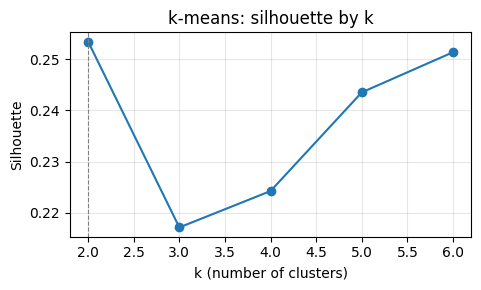

In [3]:
X = StandardScaler().fit_transform(feats[FEATS])
sil = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X)
    sil[k] = silhouette_score(X, labels)
sil = pd.Series(sil, name="silhouette")
best_k = int(sil.idxmax())
print(sil.round(3).to_string())
print(f"Best k = {best_k}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(sil.index, sil.values, marker="o")
ax.axvline(best_k, color="grey", ls="--", lw=0.8)
ax.set_xlabel("k (number of clusters)")
ax.set_ylabel("Silhouette")
ax.set_title("k-means: silhouette by k")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "fig_d2_cluster_silhouette.png", dpi=200)
plt.show()

## 3. Hierarchical clustering (Ward) and agreement with k-means

Adjusted Rand index, k-means vs Ward: 0.81
Ward      1   2
k-means        
0         2  78
1        25   3


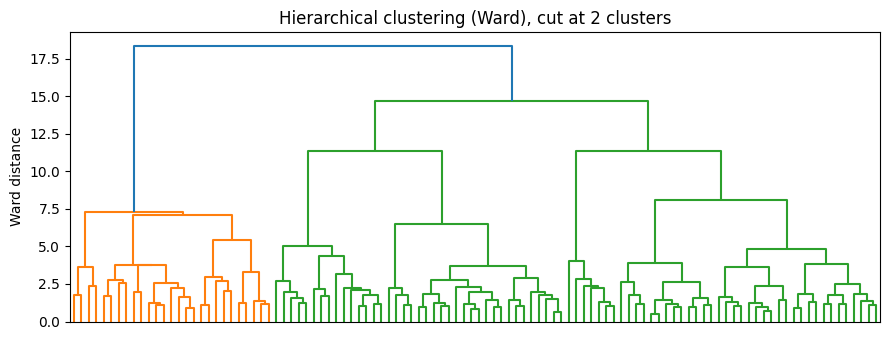

In [4]:
km = KMeans(n_clusters=best_k, n_init=20, random_state=0).fit(X)
Z = linkage(X, method="ward")
ward = fcluster(Z, best_k, criterion="maxclust")
# name the k-means clusters by seasonal share: cluster 0 = lowest (most hyperannual)
order = feats.groupby(km.labels_)["seasonal_share"].median().sort_values().index
feats["cluster"] = pd.Series(km.labels_, index=feats.index).map({c: i for i, c in enumerate(order)})
feats["ward"] = ward
print(f"Adjusted Rand index, k-means vs Ward: {adjusted_rand_score(feats.cluster, feats.ward):.2f}")
print(pd.crosstab(feats.cluster, feats.ward, rownames=["k-means"], colnames=["Ward"]).to_string())

fig, ax = plt.subplots(figsize=(9, 3.5))
dendrogram(Z, no_labels=True, color_threshold=Z[-(best_k - 1), 2], ax=ax)
ax.set_ylabel("Ward distance")
ax.set_title(f"Hierarchical clustering (Ward), cut at {best_k} clusters")
fig.tight_layout()
fig.savefig(FIGURES / "fig_d2_cluster_dendrogram.png", dpi=200)
plt.show()

## 4. What the groups look like

         reservoirs  seasonal_share  mean_pct  std_pct  lag12_autocorr  corr_spi12  corr_spi36  capacity_hm3
cluster                                                                                                     
0                80            0.09     57.15    22.31            0.48        0.48        0.39          44.0
1                28            0.10     76.76    12.26            0.34        0.09        0.01          19.0

basin    Guadiana  Júcar  Tajo
cluster                       
0              28     18    34
1               7      4    17

Key reservoirs: {'Alarcón': 0, 'Buendía': 0, 'Contreras': 0, 'Entrepeñas': 0}


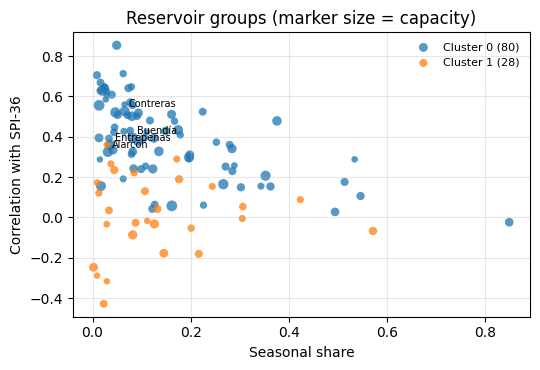

In [5]:
profile = feats.groupby("cluster")[FEATS].median()
profile.insert(0, "reservoirs", feats.groupby("cluster").size())
profile["capacity_hm3"] = np.exp(profile.pop("log_capacity")).round(0)
print(profile.round(2).to_string())
print()
print(pd.crosstab(feats.cluster, feats.basin).to_string())
KEY = ["Entrepeñas", "Buendía", "Alarcón", "Contreras"]
print("\nKey reservoirs:", feats.loc[feats.index.intersection(KEY), "cluster"].to_dict())

fig, ax = plt.subplots(figsize=(5.5, 3.8))
colors = plt.cm.tab10.colors
for c, sub in feats.groupby("cluster"):
    ax.scatter(sub.seasonal_share, sub.corr_spi36, s=12 + 6 * sub.log_capacity, color=colors[c],
               alpha=0.75, edgecolors="none", label=f"Cluster {c} ({len(sub)})")
for r in KEY:
    if r in feats.index:
        ax.annotate(r, (feats.loc[r, "seasonal_share"], feats.loc[r, "corr_spi36"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Seasonal share")
ax.set_ylabel("Correlation with SPI-36")
ax.set_title("Reservoir groups (marker size = capacity)")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "fig_d2_cluster_profiles.png", dpi=200)
plt.show()
feats.round(4).to_csv(D2_TABLES / "reservoir_clusters.csv")

**Conclusion (H4).** The silhouette is highest for k = 2 (0.25: a weak but real structure), and Ward clustering finds almost the same split (adjusted Rand index 0.81).
The two groups are *not* "seasonal vs hyperannual" inside the study basins (both have a median seasonal share of about 0.1). **Cluster 0** (80 reservoirs, including all four key reservoirs) holds regulating reservoirs that empty and refill with rainfall (median correlation with SPI-36 0.39, standard deviation 22 points). **Cluster 1** (28) holds reservoirs kept almost full whatever the rain (median 77% full, standard deviation 12, correlation with SPI close to 0), many of them hydropower dams on the main rivers (Cedillo, Azután, Bolarque; 39% have the hydropower flag, against 3% in cluster 0).
This partly supports **H4**: the reservoirs do need different treatment, but the split is by *operation*, not by seasonality. For cluster 1 rainfall features will add little and persistence will be hard to beat, so Deliverable 3 will report skill per cluster. The seasonal-vs-hyperannual contrast is between the study basins and the Duero (notebook 1.0).

## 5. BigML comparison (variety of tools)

Steps done in BigML (screenshots in `reports/deliverable_2/bigml/`):

1. Upload `reports/deliverable_2/tables/reservoir_features.csv` → **Source**. In the source configuration set **Locale = English (US)**; with a Spanish or Turkish browser locale BigML reads the decimal point as a thousands separator. Then **1-click Dataset**.
2. In the dataset, exclude `reservoir` and `basin` (identifiers, not behaviour).
3. **Cluster** → configure: algorithm **K-means**, **k = BEST_K**, *balance fields* on (BigML standardises like our scaler).
4. **Batch centroid** of the cluster on the same dataset → download as `reports/deliverable_2/bigml/bigml_clusters.csv`.

The cell below compares the BigML groups with ours once `bigml_clusters.csv` is in `reports/deliverable_2/bigml/`.

In [6]:
bigml_file = D2_TABLES.parent / "bigml" / "bigml_clusters.csv"
if bigml_file.exists():
    b = pd.read_csv(bigml_file)
    b = b.set_index(b.columns[0]) if "reservoir" not in b.columns else b.set_index("reservoir")
    centroid_col = [c for c in b.columns if "centroid" in c.lower() or "cluster" in c.lower()][0]
    both = feats.join(b[centroid_col].rename("bigml"), how="inner")
    print(f"Reservoirs matched: {len(both)}")
    print(f"Adjusted Rand index, Python k-means vs BigML: {adjusted_rand_score(both.cluster, both.bigml):.2f}")
    print(pd.crosstab(both.cluster, both.bigml, rownames=["Python"], colnames=["BigML"]).to_string())
else:
    print("bigml_clusters.csv not added yet")

Reservoirs matched: 108
Adjusted Rand index, Python k-means vs BigML: 0.75
BigML   Cluster 0  Cluster 1
Python                      
0               7         73
1              28          0


**Comparison with BigML.** The same table was clustered in BigML (K-means, k = 2, `reservoir` and `basin` excluded, fields auto-scaled). BigML finds groups of 73 and 35 reservoirs: 101 of the 108 reservoirs (94%) fall in the same group as in Python, and the adjusted Rand index is 0.75. All 28 reservoirs of our "kept full" cluster are also together in BigML; the 7 differences are reservoirs that Python puts in the regulating cluster and BigML in the "kept full" one, i.e. cases near the boundary. This is expected with a silhouette of only 0.25 and with the different initialisation and scaling of the two tools, and it confirms that the two-group structure is not an artefact of one implementation.

**Lesson learned.** BigML first read the CSV with the browser's Turkish locale, where "." is a thousands separator (0.1266 became 1266). The resulting clusters were meaningless; setting the source locale to *English (US)* fixed it. Tool settings must be checked before comparing results.